# Project Title:  Motor-Imagery EEG Classification Using Graph Neural Networks with Functional Channel Connectivity


In [1]:
!pip -q install mne scipy scikit-learn seaborn plotly umap-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.7/7.7 MB 77.3 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
moviepy 1.0.3 requires decorator<5.0,>=4.0.2, but you have decorator 5.3.1 which is incompatible.


# Uploading Important Libraries for EDA and .mat and .gdf files

In [2]:
import os
import glob
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.io as sio
import mne
import plotly.express as px

from scipy.stats import skew, kurtosis
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.feature_selection import VarianceThreshold
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score,
    f1_score, classification_report,
    confusion_matrix
)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)

print("MNE:", mne.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

MNE: 1.13.2
NumPy: 2.1.3
Pandas: 2.2.3


# Connect to the Drive

In [3]:
from google.colab import drive

drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
# To inspect Drive folders that do not need to move or upload the files again.
DRIVE_ROOT = "/content/drive/MyDrive/475_mini_proj"

for root, dirs, files in os.walk(DRIVE_ROOT):
    # Avoid scanning huge unrelated folders indefinitely.
    dirs[:] = [
        d for d in dirs
        if d not in {
            ".ipynb_checkpoints",
            "node_modules",
            ".git"
        }
    ]

    relevant = [
        f for f in files
        if f.lower().endswith((".gdf", ".mat"))
    ]

    if relevant:
        print(f"\nFolder: {root}")
        for f in relevant[:20]:
            print("  ", f)


Folder: /content/drive/MyDrive/475_mini_proj/dataset_1/Dts_1/BCICIV_1_mat
   BCICIV_calib_ds1a.mat
   BCICIV_calib_ds1b.mat
   BCICIV_calib_ds1c.mat
   BCICIV_calib_ds1d.mat
   BCICIV_calib_ds1e.mat
   BCICIV_calib_ds1f.mat
   BCICIV_calib_ds1g.mat
   BCICIV_eval_ds1a.mat
   BCICIV_eval_ds1b.mat
   BCICIV_eval_ds1c.mat
   BCICIV_eval_ds1d.mat
   BCICIV_eval_ds1e.mat
   BCICIV_eval_ds1f.mat
   BCICIV_eval_ds1g.mat

Folder: /content/drive/MyDrive/475_mini_proj/dataset_2/A/Dts_2a/BCICIV_2a_gdf
   A01E.gdf
   A01T.gdf
   A02E.gdf
   A02T.gdf
   A03E.gdf
   A03T.gdf
   A04E.gdf
   A04T.gdf
   A05E.gdf
   A05T.gdf
   A06E.gdf
   A06T.gdf
   A07E.gdf
   A07T.gdf
   A08E.gdf
   A08T.gdf
   A09E.gdf
   A09T.gdf

Folder: /content/drive/MyDrive/475_mini_proj/dataset_2/B/Dts_2b/BCICIV_2b_gdf
   B0101T.gdf
   B0102T.gdf
   B0103T.gdf
   B0104E.gdf
   B0105E.gdf
   B0201T.gdf
   B0202T.gdf
   B0203T.gdf
   B0204E.gdf
   B0205E.gdf
   B0301T.gdf
   B0302T.gdf
   B0303T.gdf
   B0304E.gdf
   B0305E.gd

In [45]:
DATA_DIR = "/content/drive/MyDrive/475_mini_proj"

assert os.path.isdir(DATA_DIR), (
    f"Folder not found: {DATA_DIR}. "
    "Update DATA_DIR to your actual Google Drive folder."
)

# Recursively find GDF and MAT files in all subdirectories
gdf_files = []
mat_files = []
for root, _, files in os.walk(DATA_DIR):
    for f in files:
        file_path = os.path.join(root, f)
        if f.lower().endswith(".gdf"):
            gdf_files.append(file_path)
        elif f.lower().endswith(".mat"):
            mat_files.append(file_path)

gdf_files = sorted(gdf_files)
mat_files = sorted(mat_files)

print("GDF files:", len(gdf_files))
print("MAT files:", len(mat_files))

display(pd.DataFrame({
    "GDF files": pd.Series([os.path.basename(f) for f in gdf_files]),
    "MAT files": pd.Series([os.path.basename(f) for f in mat_files])
}))

GDF files: 63
MAT files: 19


,GDF files,MAT files
0,A01E.gdf,BCICIV_calib_ds1a.mat
1,A01T.gdf,BCICIV_calib_ds1b.mat
2,A02E.gdf,BCICIV_calib_ds1c.mat
3,A02T.gdf,BCICIV_calib_ds1d.mat
4,A03E.gdf,BCICIV_calib_ds1e.mat
...,...,...
58,B0901T.gdf,NaN
59,B0902T.gdf,NaN
60,B0903T.gdf,NaN
61,B0904E.gdf,NaN


*This dataset's .mat files may contain preprocessed EEG, extracted features, labels, or model-ready arrays. Their structure is not necessarily the same as the original GDF recordings. Inspecting them before combining the two formats.italicized text*

# *Inspect all MAT files*

In [7]:
def inspect_mat_file(file_path):
    print(f"\nFILE: {os.path.basename(file_path)}")

    try:
        mat = sio.loadmat(file_path)
    except Exception as e:
        print(f"Error loading {file_path}: {e}")
        return

    for key, value in mat.items():
        if key.startswith("__"):
            continue

        if isinstance(value, np.ndarray):
            print(
                f"  {key}: shape={value.shape}, "
                f"dtype={value.dtype}"
            )
        else:
            print(f"  {key}: type={type(value)}")

# Find .mat files recursively in subdirectories
all_mat_files = []
for root, dirs, files in os.walk(DATA_DIR):
    for f in files:
        if f.lower().endswith(".mat"):
            all_mat_files.append(os.path.join(root, f))

print(f"Found {len(all_mat_files)} total .mat files.")

# Inspect the first 5 found .mat files
for file_path in sorted(all_mat_files)[:5]:
    inspect_mat_file(file_path)

Found 19 total .mat files.

FILE: BCICIV_calib_ds1a.mat
  mrk: shape=(1, 1), dtype=[('pos', 'O'), ('y', 'O')]
  cnt: shape=(190594, 59), dtype=int16
  nfo: shape=(1, 1), dtype=[('fs', 'O'), ('classes', 'O'), ('clab', 'O'), ('xpos', 'O'), ('ypos', 'O')]

FILE: BCICIV_calib_ds1b.mat
  mrk: shape=(1, 1), dtype=[('pos', 'O'), ('y', 'O')]
  cnt: shape=(190594, 59), dtype=int16
  nfo: shape=(1, 1), dtype=[('fs', 'O'), ('classes', 'O'), ('clab', 'O'), ('xpos', 'O'), ('ypos', 'O')]

FILE: BCICIV_calib_ds1c.mat
  mrk: shape=(1, 1), dtype=[('pos', 'O'), ('y', 'O')]
  cnt: shape=(190549, 59), dtype=int16
  nfo: shape=(1, 1), dtype=[('fs', 'O'), ('classes', 'O'), ('clab', 'O'), ('xpos', 'O'), ('ypos', 'O')]

FILE: BCICIV_calib_ds1d.mat
  mrk: shape=(1, 1), dtype=[('pos', 'O'), ('y', 'O')]
  cnt: shape=(190473, 59), dtype=int16
  nfo: shape=(1, 1), dtype=[('fs', 'O'), ('classes', 'O'), ('clab', 'O'), ('xpos', 'O'), ('ypos', 'O')]

FILE: BCICIV_calib_ds1e.mat
  mrk: shape=(1, 1), dtype=[('pos', 'O')

# *Read GDF file*

Found 9 training GDF files.
Loading first file: /content/drive/MyDrive/475_mini_proj/dataset_2/A/Dts_2a/BCICIV_2a_gdf/A01T.gdf
<RawGDF | A01T.gdf, 25 x 672528 (2690.1 s), ~128.3 MiB, data loaded>
Sampling frequency: 250.0
Total channels: 25
Channel names: ['EEG-Fz', 'EEG-0', 'EEG-1', 'EEG-2', 'EEG-3', 'EEG-4', 'EEG-5', 'EEG-C3', 'EEG-6', 'EEG-Cz', 'EEG-7', 'EEG-C4', 'EEG-8', 'EEG-9', 'EEG-10', 'EEG-11', 'EEG-12', 'EEG-13', 'EEG-14', 'EEG-Pz', 'EEG-15', 'EEG-16', 'EOG-left', 'EOG-central', 'EOG-right']
For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`


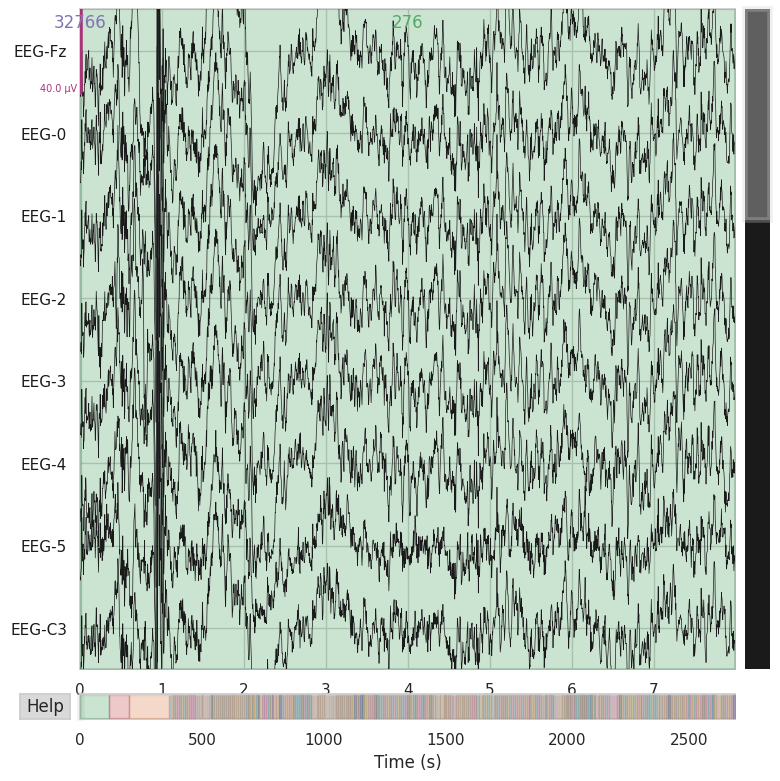

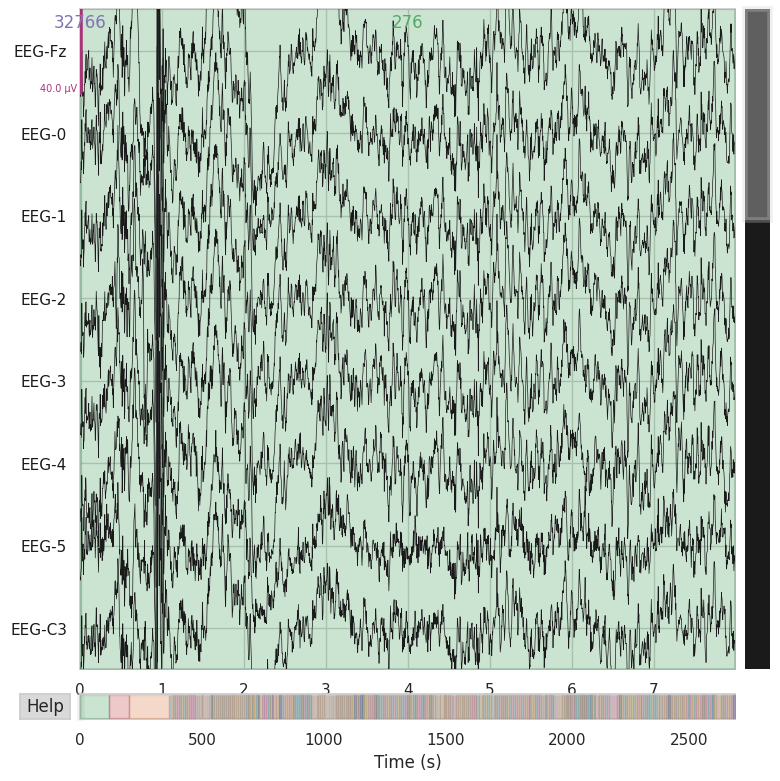

In [14]:
# Find all GDF files recursively in subdirectories
all_gdf_files = []
for root_dir, _, filenames in os.walk(DATA_DIR):
    for f in filenames:
        if f.lower().endswith(".gdf"):
            all_gdf_files.append(os.path.join(root_dir, f))

# Filter for training files using regex
import re
train_gdf = [
    f for f in all_gdf_files
    if re.search(r"A\d{2}T\.gdf$", os.path.basename(f), re.I)
]

assert train_gdf, "No training GDF files found. Check the folder and filenames."

print(f"Found {len(train_gdf)} training GDF files.")
print("Loading first file:", train_gdf[0])

raw = mne.io.read_raw_gdf(
    train_gdf[0],
    preload=True,
    verbose="ERROR"
)

print(raw)
print("Sampling frequency:", raw.info["sfreq"])
print("Total channels:", len(raw.ch_names))
print("Channel names:", raw.ch_names)

# Plot a segment of the data
raw.plot(duration = 8, n_channels = min(8, len(raw.ch_names)))

# **EDA - A ( Creat a summary )**

In [16]:
# Combine our recursively found files instead of the empty shallow lists
all_files = all_gdf_files + all_mat_files

file_summary = []

for path in all_files:
    file_summary.append({
        "file_name": os.path.basename(path),
        "extension": Path(path).suffix.lower(),
        "size_MB": round(os.path.getsize(path) / (1024**2), 2),
        "file_path": path
    })

file_summary_df = pd.DataFrame(file_summary)

display(file_summary_df)
print("Total files:", len(file_summary_df))
print("Total size (MB):", round(file_summary_df["size_MB"].sum(), 2))

,file_name,extension,size_MB,file_path
0,A01E.gdf,.gdf,32.77,/content/drive/MyDrive/475_mini_proj/dataset_2...
1,A01T.gdf,.gdf,32.08,/content/drive/MyDrive/475_mini_proj/dataset_2...
2,A02E.gdf,.gdf,31.61,/content/drive/MyDrive/475_mini_proj/dataset_2...
3,A02T.gdf,.gdf,32.30,/content/drive/MyDrive/475_mini_proj/dataset_2...
4,A03E.gdf,.gdf,30.95,/content/drive/MyDrive/475_mini_proj/dataset_2...
...,...,...,...,...
77,S1.mat,.mat,7.15,/content/drive/MyDrive/475_mini_proj/dataset_3...
78,S2.mat,.mat,7.12,/content/drive/MyDrive/475_mini_proj/dataset_3...
79,sub1_comp.mat,.mat,133.51,/content/drive/MyDrive/475_mini_proj/dataset_4...
80,sub2_comp.mat,.mat,125.12,/content/drive/MyDrive/475_mini_proj/dataset_4...


Total files: 82
Total size (MB): 1571.51


GDF Files

In [18]:
recording_summary = []

# Changed loop from 'gdf_files' to 'all_gdf_files' which contains the actual paths
for path in all_gdf_files:
    try:
        r = mne.io.read_raw_gdf(
            path, preload=False, verbose="ERROR"
        )

        recording_summary.append({
            "file": os.path.basename(path),
            "sampling_rate_Hz": r.info["sfreq"],
            "total_channels": len(r.ch_names),
            "duration_seconds": round(r.n_times / r.info["sfreq"], 2),
            "channel_names": ", ".join(r.ch_names)
        })

        del r

    except Exception as e:
        recording_summary.append({
            "file": os.path.basename(path),
            "error": str(e)
        })

recording_summary_df = pd.DataFrame(recording_summary)
display(recording_summary_df)

,file,sampling_rate_Hz,total_channels,duration_seconds,channel_names
0,A01E.gdf,250.0,25,2748.00,"EEG-Fz, EEG-0, EEG-1, EEG-2, EEG-3, EEG-4, EEG..."
1,A01T.gdf,250.0,25,2690.11,"EEG-Fz, EEG-0, EEG-1, EEG-2, EEG-3, EEG-4, EEG..."
2,A02E.gdf,250.0,25,2650.66,"EEG-Fz, EEG-0, EEG-1, EEG-2, EEG-3, EEG-4, EEG..."
3,A02T.gdf,250.0,25,2708.68,"EEG-Fz, EEG-0, EEG-1, EEG-2, EEG-3, EEG-4, EEG..."
4,A03E.gdf,250.0,25,2595.10,"EEG-Fz, EEG-0, EEG-1, EEG-2, EEG-3, EEG-4, EEG..."
...,...,...,...,...,...
58,B0901T.gdf,250.0,6,2419.21,"EEG:C3, EEG:Cz, EEG:C4, EOG:ch01, EOG:ch02, EO..."
59,B0902T.gdf,250.0,6,2419.21,"EEG:C3, EEG:Cz, EEG:C4, EOG:ch01, EOG:ch02, EO..."
60,B0903T.gdf,250.0,6,1842.92,"EEG:C3, EEG:Cz, EEG:C4, EOG:ch01, EOG:ch02, EO..."
61,B0904E.gdf,250.0,6,1867.21,"EEG:C3, EEG:Cz, EEG:C4, EOG:ch01, EOG:ch02, EO..."


It gives us the recording-level summary. Later, add per-subject trial counts, extracted feature counts and missing-value counts.

**Prepared labeled EEG Epoch**

In [19]:
import re
# Inspect the event codes in the first recording
events, event_id = mne.events_from_annotations(raw)

print("Annotation event IDs:")
print(event_id)

print("\nUnique event codes:")
print(np.unique(events[:, 2], return_counts=True))

# Define a function that extracts the four classes from one GDF file
CLASS_CODES = {
    "Left hand": 769,
    "Right hand": 770,
    "Both feet": 771,
    "Tongue": 772
}

def load_gdf_epochs(file_path):
    """
    Load one BCI IV-2a GDF training file and extract
    four-second EEG epochs for the four motor-imagery classes.
    """
    raw = mne.io.read_raw_gdf(
        file_path,
        preload=True,
        verbose="ERROR"
    )

    # Convert annotations to MNE events.
    events, annotation_ids = mne.events_from_annotations(
        raw, verbose="ERROR"
    )

    # Map annotation descriptions to their integer event codes.
    code_to_event = {
        int(description): event_code
        for description, event_code in annotation_ids.items()
        if str(description).isdigit()
    }

    selected_event_id = {
        label: code_to_event[code]
        for label, code in CLASS_CODES.items()
        if code in code_to_event
    }

    if len(selected_event_id) != 4:
        raise ValueError(
            f"Expected all four class codes in {file_path}. "
            f"Found: {selected_event_id}. "
            f"Inspect annotations before proceeding."
        )

    # Retain EEG channels, excluding EOG channels.
    eeg_raw = raw.copy().pick("eeg")

    # Use 4 seconds at 250 Hz: 1,000 samples.
    epochs = mne.Epochs(
        eeg_raw,
        events,
        event_id=selected_event_id,
        tmin=0.0,
        tmax=3.996,
        baseline=None,
        preload=True,
        reject_by_annotation=True,
        event_repeated="error",
        verbose="ERROR"
    )

    X = epochs.get_data(units="uV").astype(np.float32)
    y = epochs.events[:, 2]

    # Convert event codes to readable class names.
    inverse_codes = {
        code_to_event[code]: label
        for label, code in CLASS_CODES.items()
        if code in code_to_event
    }

    y_names = np.array([inverse_codes[c] for c in y])

    metadata = pd.DataFrame({
        "subject": Path(file_path).stem[:3],
        "trial_index": np.arange(len(y)),
        "class": y_names,
        "source_file": os.path.basename(file_path)
    })

    return X, y_names, metadata, epochs.ch_names, epochs.info["sfreq"]

Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '769', '770', '771', '772']
Annotation event IDs:
{'1023': 1, '1072': 2, '276': 3, '277': 4, '32766': 5, '768': 6, '769': 7, '770': 8, '771': 9, '772': 10}

Unique event codes:
(array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10]), array([ 15,   1,   1,   1,   9, 288,  72,  72,  72,  72]))


In [20]:
X_one, y_one, meta_one, channel_names, sfreq = load_gdf_epochs(
    train_gdf[0]
)

print("Epoch tensor shape:", X_one.shape)
print("Labels shape:", y_one.shape)
print("Sampling rate:", sfreq)
print("Number of EEG channels:", len(channel_names))
print("Class counts:")
print(pd.Series(y_one).value_counts())

Epoch tensor shape: (288, 25, 1000)
Labels shape: (288,)
Sampling rate: 250.0
Number of EEG channels: 25
Class counts:
Tongue        72
Both feet     72
Right hand    72
Left hand     72
Name: count, dtype: int64


Loading all 9 training subjects

In [21]:
X_list = []
y_list = []
metadata_list = []

for file_path in train_gdf:
    X_sub, y_sub, meta_sub, ch_names, sf = load_gdf_epochs(file_path)

    X_list.append(X_sub)
    y_list.append(y_sub)
    metadata_list.append(meta_sub)

    print(
        os.path.basename(file_path),
        "epochs:", X_sub.shape[0],
        "shape:", X_sub.shape
    )

X = np.concatenate(X_list, axis=0)
y = np.concatenate(y_list)
metadata = pd.concat(metadata_list, ignore_index=True)

print("\nCombined X shape:", X.shape)
print("Combined labels:", y.shape)
print("Combined metadata:", metadata.shape)

A01T.gdf epochs: 288 shape: (288, 25, 1000)
A02T.gdf epochs: 288 shape: (288, 25, 1000)
A03T.gdf epochs: 288 shape: (288, 25, 1000)
A04T.gdf epochs: 288 shape: (288, 25, 1000)
A05T.gdf epochs: 288 shape: (288, 25, 1000)
A06T.gdf epochs: 288 shape: (288, 25, 1000)
A07T.gdf epochs: 288 shape: (288, 25, 1000)
A08T.gdf epochs: 288 shape: (288, 25, 1000)
A09T.gdf epochs: 288 shape: (288, 25, 1000)

Combined X shape: (2592, 25, 1000)
Combined labels: (2592,)
Combined metadata: (2592, 4)


# **EDA - B (statistcis) **

In [22]:
# Flatten all trials and time points for each EEG channel.
raw_channel_df = pd.DataFrame(
    X.transpose(1, 0, 2).reshape(len(channel_names), -1).T,
    columns=channel_names
)

def descriptive_statistics(df):
    result = pd.DataFrame(index=df.columns)

    result["mean"] = df.mean()
    result["median"] = df.median()
    result["std"] = df.std()
    result["min"] = df.min()
    result["Q1"] = df.quantile(0.25)
    result["Q2"] = df.quantile(0.50)
    result["Q3"] = df.quantile(0.75)
    result["max"] = df.max()
    result["skewness"] = df.skew()
    result["kurtosis_excess"] = df.kurtosis()

    return result

channel_stats = descriptive_statistics(raw_channel_df)

display(channel_stats.round(4))

,mean,median,std,min,Q1,Q2,Q3,max,skewness,kurtosis_excess
EEG-Fz,0.2546,0.0977,11.4846,-100.0,-6.7383,0.0977,7.0312,99.951202,0.2524,3.170000
EEG-0,0.2998,0.1953,10.4299,-100.0,-6.1523,0.1953,6.5918,99.951202,0.1286,2.380400
EEG-1,0.2901,0.1953,11.0774,-100.0,-6.6406,0.1953,7.0801,99.951202,0.1124,1.858000
EEG-2,0.2907,0.1953,11.6386,-100.0,-7.0312,0.1953,7.4707,99.951202,0.1045,1.597000
EEG-3,0.2875,0.1953,11.3527,-100.0,-6.8359,0.1953,7.2754,99.951202,0.1034,1.581900
EEG-4,0.3174,0.1953,11.0715,-100.0,-6.5430,0.1953,7.0312,99.951202,0.1373,2.150400
EEG-5,0.3768,0.2441,8.8773,-100.0,-5.0293,0.2441,5.6641,99.951202,0.0840,2.750500
EEG-C3,0.3589,0.2930,10.1803,-100.0,-5.9082,0.2930,6.5430,99.951202,0.0138,1.679300
EEG-6,0.3039,0.1953,10.7879,-100.0,-6.4941,0.1953,6.9824,99.951202,0.0620,1.206700
EEG-Cz,0.2983,0.1953,11.4883,-100.0,-6.9336,0.1953,7.4219,99.951202,0.0993,1.672700


Visualize the channel distribution

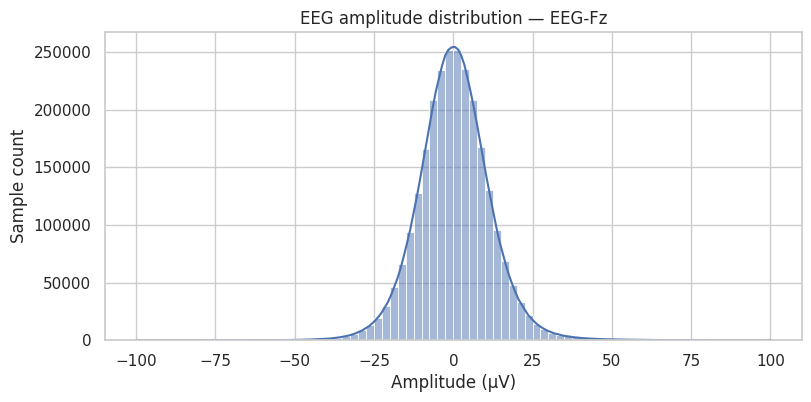

In [23]:
channel_to_plot = channel_names[0]

plt.figure(figsize=(9, 4))
sns.histplot(
    raw_channel_df[channel_to_plot],
    bins=80,
    kde=True
)
plt.title(f"EEG amplitude distribution — {channel_to_plot}")
plt.xlabel("Amplitude (µV)")
plt.ylabel("Sample count")
plt.show()

Identify potential Outliers

Use the interquartile range (IQR) as an initial flagging method

In [24]:
def iqr_outlier_summary(df):
    rows = []

    for col in df.columns:
        q1 = df[col].quantile(0.25)
        q3 = df[col].quantile(0.75)
        iqr = q3 - q1

        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr

        count = ((df[col] < lower) | (df[col] > upper)).sum()

        rows.append({
            "channel": col,
            "lower_bound": lower,
            "upper_bound": upper,
            "outlier_samples": int(count),
            "outlier_percentage": 100 * count / len(df)
        })

    return pd.DataFrame(rows)

outlier_summary = iqr_outlier_summary(raw_channel_df)
display(outlier_summary.round(3))

,channel,lower_bound,upper_bound,outlier_samples,outlier_percentage
0,EEG-Fz,-27.393,27.686,60677,2.341
1,EEG-0,-25.269,25.708,56106,2.165
2,EEG-1,-27.222,27.661,51233,1.977
3,EEG-2,-28.784,29.224,49989,1.929
4,EEG-3,-28.003,28.442,50532,1.950
5,EEG-4,-26.904,27.393,55153,2.128
6,EEG-5,-21.069,21.704,62299,2.404
7,EEG-C3,-24.585,25.220,58434,2.254
8,EEG-6,-26.709,27.197,48854,1.885
9,EEG-Cz,-28.467,28.955,47160,1.819


# EDA - C (data quality)

In [25]:
# Check missing values and invalid values
missing_samples = np.isnan(X).sum()
infinite_samples = np.isinf(X).sum()
total_samples = X.size

quality_summary = pd.DataFrame({
    "check": ["NaN samples", "Infinite samples"],
    "count": [missing_samples, infinite_samples],
    "percentage": [
        100 * missing_samples / total_samples,
        100 * infinite_samples / total_samples
    ]
})

display(quality_summary)

,check,count,percentage
0,NaN samples,0,0.0
1,Infinite samples,0,0.0


Check duplicate epochs.  

In [26]:
# Exact duplicates across the full epoch tensor.
flat_X = X.reshape(len(X), -1)

_, unique_indices = np.unique(
    flat_X,
    axis=0,
    return_index=True
)

exact_duplicate_count = len(X) - len(unique_indices)

print("Exact duplicate epochs:", exact_duplicate_count)

metadata_duplicates = metadata.duplicated(
    subset=["subject", "trial_index"]
).sum()

print("Duplicate subject/trial metadata records:", metadata_duplicates)

Exact duplicate epochs: 0
Duplicate subject/trial metadata records: 0


In [27]:
# Check near-constant channel
variance_by_channel = raw_channel_df.var()

near_constant = variance_by_channel[
    variance_by_channel < 1e-6
]

print("Potential near-constant channels:")
display(near_constant.rename("variance").to_frame())

Potential near-constant channels:


,variance


In [28]:
# Check highly correlated channels
corr = raw_channel_df.corr(method="pearson")

upper_triangle = corr.where(
    np.triu(np.ones(corr.shape), k=1).astype(bool)
)

threshold = 0.90

high_corr_pairs = (
    upper_triangle.stack()
    .reset_index()
)

high_corr_pairs.columns = ["channel_1", "channel_2", "correlation"]

high_corr_pairs = high_corr_pairs[
    high_corr_pairs["correlation"].abs() >= threshold
].sort_values(
    "correlation",
    key=lambda s: s.abs(),
    ascending=False
)

display(high_corr_pairs)

,channel_1,channel_2,correlation
279,EEG-14,EEG-Pz,0.973561
285,EEG-Pz,EEG-15,0.971924
47,EEG-1,EEG-2,0.966055
245,EEG-10,EEG-11,0.962477
69,EEG-2,EEG-3,0.961790
...,...,...,...
201,EEG-7,EEG-13,0.904462
238,EEG-9,EEG-14,0.901998
54,EEG-1,EEG-7,0.901173
153,EEG-C3,EEG-10,0.900628


# EDA - D (class balace and graph chart)

In [29]:
# Checking the actual class distribution after epoch extraction and annotation rejection

class_counts = pd.Series(y, name="class").value_counts()

class_order = [
    "Left hand", "Right hand", "Both feet", "Tongue"
]

class_counts = class_counts.reindex(class_order, fill_value=0)

class_balance = pd.DataFrame({
    "class": class_counts.index,
    "count": class_counts.values,
    "percentage": 100 * class_counts.values / len(y)
})

display(class_balance)

fig = px.bar(
    class_balance,
    x="class",
    y="count",
    color="class",
    text="count",
    title="EDA D: Motor-imagery class distribution",
    labels={"class": "Motor-imagery class", "count": "Number of trials"}
)

fig.show()

,class,count,percentage
0,Left hand,648,25.0
1,Right hand,648,25.0
2,Both feet,648,25.0
3,Tongue,648,25.0


Equal bar heights indicate balanced class counts in the retained dataset. If counts differ, investigate rejected epochs and missing event annotations. Report macro-F1 and balanced accuracy in addition to accuracy if imbalance is present.

class,Left hand,Right hand,Both feet,Tongue
subject,,,,
A01,72,72,72,72
A02,72,72,72,72
A03,72,72,72,72
A04,72,72,72,72
A05,72,72,72,72
A06,72,72,72,72
A07,72,72,72,72
A08,72,72,72,72
A09,72,72,72,72


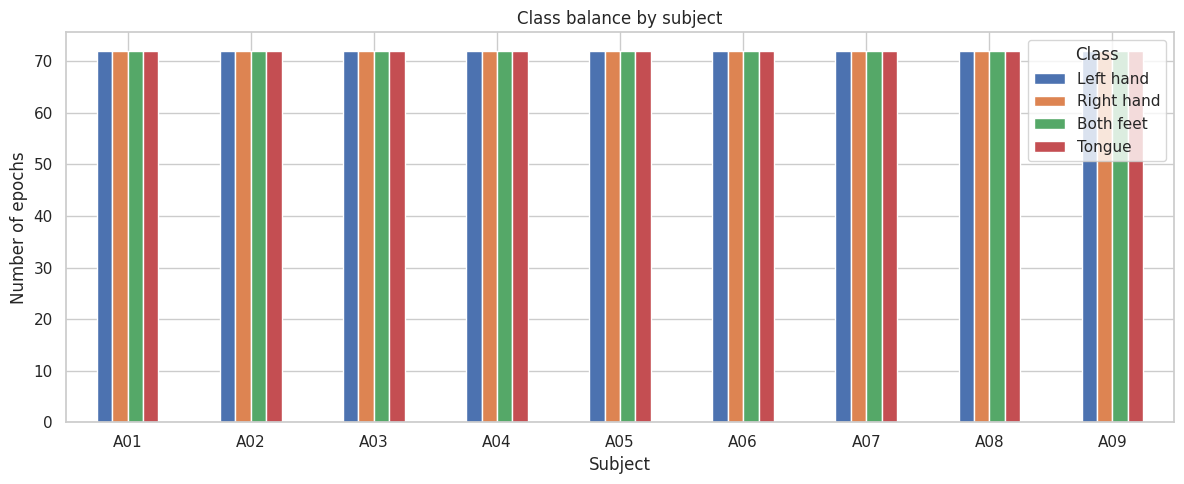

In [30]:
# checking the distribution for each subject
subject_class_counts = pd.crosstab(
    metadata["subject"], metadata["class"]
).reindex(columns=class_order, fill_value=0)

display(subject_class_counts)

subject_class_counts.plot(
    kind="bar",
    figsize=(12, 5)
)
plt.title("Class balance by subject")
plt.xlabel("Subject")
plt.ylabel("Number of epochs")
plt.xticks(rotation=0)
plt.legend(title="Class")
plt.tight_layout()
plt.show()

# **Extract features for E, F and G**
For our GNN project, this project is starting with interpretable features before attempting complex learned representations.

We will extract:
- Log-variance per EEG channel.
- Relative power in the theta, alpha/mu, beta and gamma bands.
- One feature vector per epoch.
The example below uses Welch's power spectral density (PSD). The frequency bands are configurable and should be documented in our methodology.

In [31]:
from scipy.signal import welch

BANDS = {
    "theta": (4, 8),
    "mu_alpha": (8, 13),
    "beta": (13, 30),
    "gamma": (30, 40)
}

def extract_epoch_features(X, channel_names, sfreq):
    """
    Create a tabular feature matrix.
    X shape: (trials, channels, time_samples)
    """
    feature_rows = []

    for trial_idx in range(X.shape[0]):
        row = {}

        for ch_idx, ch_name in enumerate(channel_names):
            signal = X[trial_idx, ch_idx, :]

            # Log-variance.
            row[f"{ch_name}_logvar"] = np.log(
                np.var(signal) + 1e-12
            )

            # PSD.
            freqs, psd = welch(
                signal,
                fs=sfreq,
                nperseg=min(256, len(signal))
            )

            total_power = np.trapezoid(psd, freqs) + 1e-12

            for band_name, (low, high) in BANDS.items():
                mask = (freqs >= low) & (freqs < high)

                if mask.sum() >= 2:
                    band_power = np.trapezoid(
                        psd[mask], freqs[mask]
                    )
                elif mask.sum() == 1:
                    band_power = psd[mask][0] * (
                        freqs[1] - freqs[0]
                    )
                else:
                    band_power = 0.0

                relative_power = band_power / total_power

                row[f"{ch_name}_{band_name}_relpower"] = (
                    relative_power
                )

        feature_rows.append(row)

    return pd.DataFrame(feature_rows)


feature_df = extract_epoch_features(
    X, channel_names, sfreq
)

print("Feature matrix shape:", feature_df.shape)
display(feature_df.head())

Feature matrix shape: (2592, 125)


,EEG-Fz_logvar,EEG-Fz_theta_relpower,EEG-Fz_mu_alpha_relpower,EEG-Fz_beta_relpower,EEG-Fz_gamma_relpower,EEG-0_logvar,EEG-0_theta_relpower,EEG-0_mu_alpha_relpower,EEG-0_beta_relpower,EEG-0_gamma_relpower,EEG-1_logvar,EEG-1_theta_relpower,EEG-1_mu_alpha_relpower,EEG-1_beta_relpower,EEG-1_gamma_relpower,EEG-2_logvar,EEG-2_theta_relpower,EEG-2_mu_alpha_relpower,EEG-2_beta_relpower,EEG-2_gamma_relpower,EEG-3_logvar,EEG-3_theta_relpower,EEG-3_mu_alpha_relpower,EEG-3_beta_relpower,EEG-3_gamma_relpower,EEG-4_logvar,EEG-4_theta_relpower,EEG-4_mu_alpha_relpower,EEG-4_beta_relpower,EEG-4_gamma_relpower,EEG-5_logvar,EEG-5_theta_relpower,EEG-5_mu_alpha_relpower,EEG-5_beta_relpower,EEG-5_gamma_relpower,EEG-C3_logvar,EEG-C3_theta_relpower,EEG-C3_mu_alpha_relpower,EEG-C3_beta_relpower,EEG-C3_gamma_relpower,EEG-6_logvar,EEG-6_theta_relpower,EEG-6_mu_alpha_relpower,EEG-6_beta_relpower,EEG-6_gamma_relpower,EEG-Cz_logvar,EEG-Cz_theta_relpower,EEG-Cz_mu_alpha_relpower,EEG-Cz_beta_relpower,EEG-Cz_gamma_relpower,...,EEG-11_logvar,EEG-11_theta_relpower,EEG-11_mu_alpha_relpower,EEG-11_beta_relpower,EEG-11_gamma_relpower,EEG-12_logvar,EEG-12_theta_relpower,EEG-12_mu_alpha_relpower,EEG-12_beta_relpower,EEG-12_gamma_relpower,EEG-13_logvar,EEG-13_theta_relpower,EEG-13_mu_alpha_relpower,EEG-13_beta_relpower,EEG-13_gamma_relpower,EEG-14_logvar,EEG-14_theta_relpower,EEG-14_mu_alpha_relpower,EEG-14_beta_relpower,EEG-14_gamma_relpower,EEG-Pz_logvar,EEG-Pz_theta_relpower,EEG-Pz_mu_alpha_relpower,EEG-Pz_beta_relpower,EEG-Pz_gamma_relpower,EEG-15_logvar,EEG-15_theta_relpower,EEG-15_mu_alpha_relpower,EEG-15_beta_relpower,EEG-15_gamma_relpower,EEG-16_logvar,EEG-16_theta_relpower,EEG-16_mu_alpha_relpower,EEG-16_beta_relpower,EEG-16_gamma_relpower,EOG-left_logvar,EOG-left_theta_relpower,EOG-left_mu_alpha_relpower,EOG-left_beta_relpower,EOG-left_gamma_relpower,EOG-central_logvar,EOG-central_theta_relpower,EOG-central_mu_alpha_relpower,EOG-central_beta_relpower,EOG-central_gamma_relpower,EOG-right_logvar,EOG-right_theta_relpower,EOG-right_mu_alpha_relpower,EOG-right_beta_relpower,EOG-right_gamma_relpower
0,4.965297,0.133268,0.079995,0.108271,0.038873,4.778587,0.103316,0.102648,0.108619,0.030591,4.941682,0.106893,0.094834,0.109665,0.029101,5.019794,0.119044,0.086625,0.111017,0.036769,4.933959,0.107870,0.078318,0.109052,0.043613,4.803721,0.104308,0.078347,0.109369,0.055558,4.172305,0.096734,0.068117,0.108850,0.027962,4.633113,0.094293,0.074672,0.112182,0.026196,4.885983,0.096258,0.068808,0.109038,0.021907,5.017100,0.095201,0.068338,0.099147,0.023844,...,4.831303,0.093767,0.056075,0.099067,0.017786,4.795488,0.082731,0.077949,0.102070,0.018070,4.681490,0.068326,0.124842,0.124494,0.021036,4.602394,0.103618,0.078712,0.107475,0.021106,4.662865,0.092138,0.081494,0.110284,0.017370,4.601567,0.077665,0.112951,0.130299,0.016084,4.495808,0.084943,0.102633,0.184405,0.027489,3.595039,0.060885,0.051717,0.133384,0.072816,6.296380,0.203620,0.069066,0.036104,0.013012,4.025277,0.051558,0.076894,0.159448,0.088639
1,4.775268,0.125678,0.126524,0.073521,0.032589,4.757755,0.094264,0.181797,0.068853,0.028179,4.861423,0.096858,0.165595,0.075513,0.025515,4.974792,0.104365,0.126523,0.077361,0.032166,4.864005,0.099701,0.122749,0.089706,0.037340,4.726108,0.104269,0.100744,0.110578,0.050644,4.250912,0.076956,0.188946,0.097787,0.020020,4.652940,0.094363,0.195231,0.086389,0.022191,4.809933,0.095181,0.155965,0.092727,0.021791,4.911103,0.103147,0.123091,0.092302,0.027293,...,4.786626,0.109396,0.132578,0.105892,0.023339,4.744703,0.109791,0.132871,0.108977,0.024947,4.711771,0.097411,0.160046,0.130185,0.027368,4.630937,0.093125,0.199781,0.122627,0.018908,4.679681,0.097018,0.194022,0.126817,0.019348,4.648472,0.093296,0.197171,0.127478,0.018677,4.598894,0.081675,0.215650,0.168443,0.024649,3.501711,0.056596,0.052446,0.103797,0.046577,4.206150,0.141618,0.095450,0.104401,0.049112,3.850943,0.059058,0.086210,0.146590,0.073297
2,4.267907,0.088570,0.086853,0.165755,0.032136,4.218421,0.109324,0.059456,0.155740,0.028

Each row corresponds to one trial. Each column corresponds to an extracted feature.


Creating a combined feature table for EDA

In [32]:
feature_df = feature_df.replace([np.inf, -np.inf], np.nan)

eda_df = pd.concat(
    [
        metadata.reset_index(drop=True),
        feature_df.reset_index(drop=True)
    ],
    axis=1
)

print("Combined EDA table shape:", eda_df.shape)
display(eda_df.head())

Combined EDA table shape: (2592, 129)


,subject,trial_index,class,source_file,EEG-Fz_logvar,EEG-Fz_theta_relpower,EEG-Fz_mu_alpha_relpower,EEG-Fz_beta_relpower,EEG-Fz_gamma_relpower,EEG-0_logvar,EEG-0_theta_relpower,EEG-0_mu_alpha_relpower,EEG-0_beta_relpower,EEG-0_gamma_relpower,EEG-1_logvar,EEG-1_theta_relpower,EEG-1_mu_alpha_relpower,EEG-1_beta_relpower,EEG-1_gamma_relpower,EEG-2_logvar,EEG-2_theta_relpower,EEG-2_mu_alpha_relpower,EEG-2_beta_relpower,EEG-2_gamma_relpower,EEG-3_logvar,EEG-3_theta_relpower,EEG-3_mu_alpha_relpower,EEG-3_beta_relpower,EEG-3_gamma_relpower,EEG-4_logvar,EEG-4_theta_relpower,EEG-4_mu_alpha_relpower,EEG-4_beta_relpower,EEG-4_gamma_relpower,EEG-5_logvar,EEG-5_theta_relpower,EEG-5_mu_alpha_relpower,EEG-5_beta_relpower,EEG-5_gamma_relpower,EEG-C3_logvar,EEG-C3_theta_relpower,EEG-C3_mu_alpha_relpower,EEG-C3_beta_relpower,EEG-C3_gamma_relpower,EEG-6_logvar,EEG-6_theta_relpower,EEG-6_mu_alpha_relpower,EEG-6_beta_relpower,EEG-6_gamma_relpower,EEG-Cz_logvar,...,EEG-11_logvar,EEG-11_theta_relpower,EEG-11_mu_alpha_relpower,EEG-11_beta_relpower,EEG-11_gamma_relpower,EEG-12_logvar,EEG-12_theta_relpower,EEG-12_mu_alpha_relpower,EEG-12_beta_relpower,EEG-12_gamma_relpower,EEG-13_logvar,EEG-13_theta_relpower,EEG-13_mu_alpha_relpower,EEG-13_beta_relpower,EEG-13_gamma_relpower,EEG-14_logvar,EEG-14_theta_relpower,EEG-14_mu_alpha_relpower,EEG-14_beta_relpower,EEG-14_gamma_relpower,EEG-Pz_logvar,EEG-Pz_theta_relpower,EEG-Pz_mu_alpha_relpower,EEG-Pz_beta_relpower,EEG-Pz_gamma_relpower,EEG-15_logvar,EEG-15_theta_relpower,EEG-15_mu_alpha_relpower,EEG-15_beta_relpower,EEG-15_gamma_relpower,EEG-16_logvar,EEG-16_theta_relpower,EEG-16_mu_alpha_relpower,EEG-16_beta_relpower,EEG-16_gamma_relpower,EOG-left_logvar,EOG-left_theta_relpower,EOG-left_mu_alpha_relpower,EOG-left_beta_relpower,EOG-left_gamma_relpower,EOG-central_logvar,EOG-central_theta_relpower,EOG-central_mu_alpha_relpower,EOG-central_beta_relpower,EOG-central_gamma_relpower,EOG-right_logvar,EOG-right_theta_relpower,EOG-right_mu_alpha_relpower,EOG-right_beta_relpower,EOG-right_gamma_relpower
0,A01,0,Tongue,A01T.gdf,4.965297,0.133268,0.079995,0.108271,0.038873,4.778587,0.103316,0.102648,0.108619,0.030591,4.941682,0.106893,0.094834,0.109665,0.029101,5.019794,0.119044,0.086625,0.111017,0.036769,4.933959,0.107870,0.078318,0.109052,0.043613,4.803721,0.104308,0.078347,0.109369,0.055558,4.172305,0.096734,0.068117,0.108850,0.027962,4.633113,0.094293,0.074672,0.112182,0.026196,4.885983,0.096258,0.068808,0.109038,0.021907,5.017100,...,4.831303,0.093767,0.056075,0.099067,0.017786,4.795488,0.082731,0.077949,0.102070,0.018070,4.681490,0.068326,0.124842,0.124494,0.021036,4.602394,0.103618,0.078712,0.107475,0.021106,4.662865,0.092138,0.081494,0.110284,0.017370,4.601567,0.077665,0.112951,0.130299,0.016084,4.495808,0.084943,0.102633,0.184405,0.027489,3.595039,0.060885,0.051717,0.133384,0.072816,6.296380,0.203620,0.069066,0.036104,0.013012,4.025277,0.051558,0.076894,0.159448,0.088639
1,A01,1,Both feet,A01T.gdf,4.775268,0.125678,0.126524,0.073521,0.032589,4.757755,0.094264,0.181797,0.068853,0.028179,4.861423,0.096858,0.165595,0.075513,0.025515,4.974792,0.104365,0.126523,0.077361,0.032166,4.864005,0.099701,0.122749,0.089706,0.037340,4.726108,0.104269,0.100744,0.110578,0.050644,4.250912,0.076956,0.188946,0.097787,0.020020,4.652940,0.094363,0.195231,0.086389,0.022191,4.809933,0.095181,0.155965,0.092727,0.021791,4.911103,...,4.786626,0.109396,0.132578,0.105892,0.023339,4.744703,0.109791,0.132871,0.108977,0.024947,4.711771,0.097411,0.160046,0.130185,0.027368,4.630937,0.093125,0.199781,0.122627,0.018908,4.679681,0.097018,0.194022,0.126817,0.019348,4.648472,0.093296,0.197171,0.127478,0.018677,4.598894,0.081675,0.215650,0.168443,0.024649,3.501711,0.056596,0.052446,0.103797,0.046577,4.206150,0.141618,0.095450,0.104401,0.049112,3.850943,0.059058,0.086210,0.146590,0.073297
2,A01,2,Right hand,A01T.gdf,4.267907,0.088570,0.086853,0.165755,0.032136,4.218421,0.109324,0.059456,0.155740,0.028819,4.370460,0.098063,0.074398,0.157210,0.024949,4.

# EDA - E ( Histogram, boxplots, and violin plots)

In [33]:
# Choosing a feature to explore
feature_columns = feature_df.columns.tolist()

print("Number of extracted features:", len(feature_columns))
print(feature_columns[:15])

# Example feature from the first EEG channel.
example_feature = f"{channel_names[0]}_mu_alpha_relpower"

if example_feature not in eda_df.columns:
    example_feature = feature_columns[0]

print("Selected feature:", example_feature)

Number of extracted features: 125
['EEG-Fz_logvar', 'EEG-Fz_theta_relpower', 'EEG-Fz_mu_alpha_relpower', 'EEG-Fz_beta_relpower', 'EEG-Fz_gamma_relpower', 'EEG-0_logvar', 'EEG-0_theta_relpower', 'EEG-0_mu_alpha_relpower', 'EEG-0_beta_relpower', 'EEG-0_gamma_relpower', 'EEG-1_logvar', 'EEG-1_theta_relpower', 'EEG-1_mu_alpha_relpower', 'EEG-1_beta_relpower', 'EEG-1_gamma_relpower']
Selected feature: EEG-Fz_mu_alpha_relpower


**Histogram**

In [34]:
fig = px.histogram(
    eda_df,
    x=example_feature,
    color="class",
    barmode="overlay",
    opacity=0.65,
    marginal="box",
    title=f"EDA E: Distribution of {example_feature} by class"
)

fig.show()

**Boxplot**

In [35]:
fig = px.box(
    eda_df,
    x="class",
    y=example_feature,
    color="class",
    points="outliers",
    title=f"EDA E: Class-wise boxplot of {example_feature}"
)

fig.show()

**Violin plot**

In [36]:
fig = px.violin(
    eda_df,
    x="class",
    y=example_feature,
    color="class",
    box=True,
    points="outliers",
    title=f"EDA E: Violin plot of {example_feature}"
)

fig.show()

# EDA - F (Correlation heatmap and redundant features)

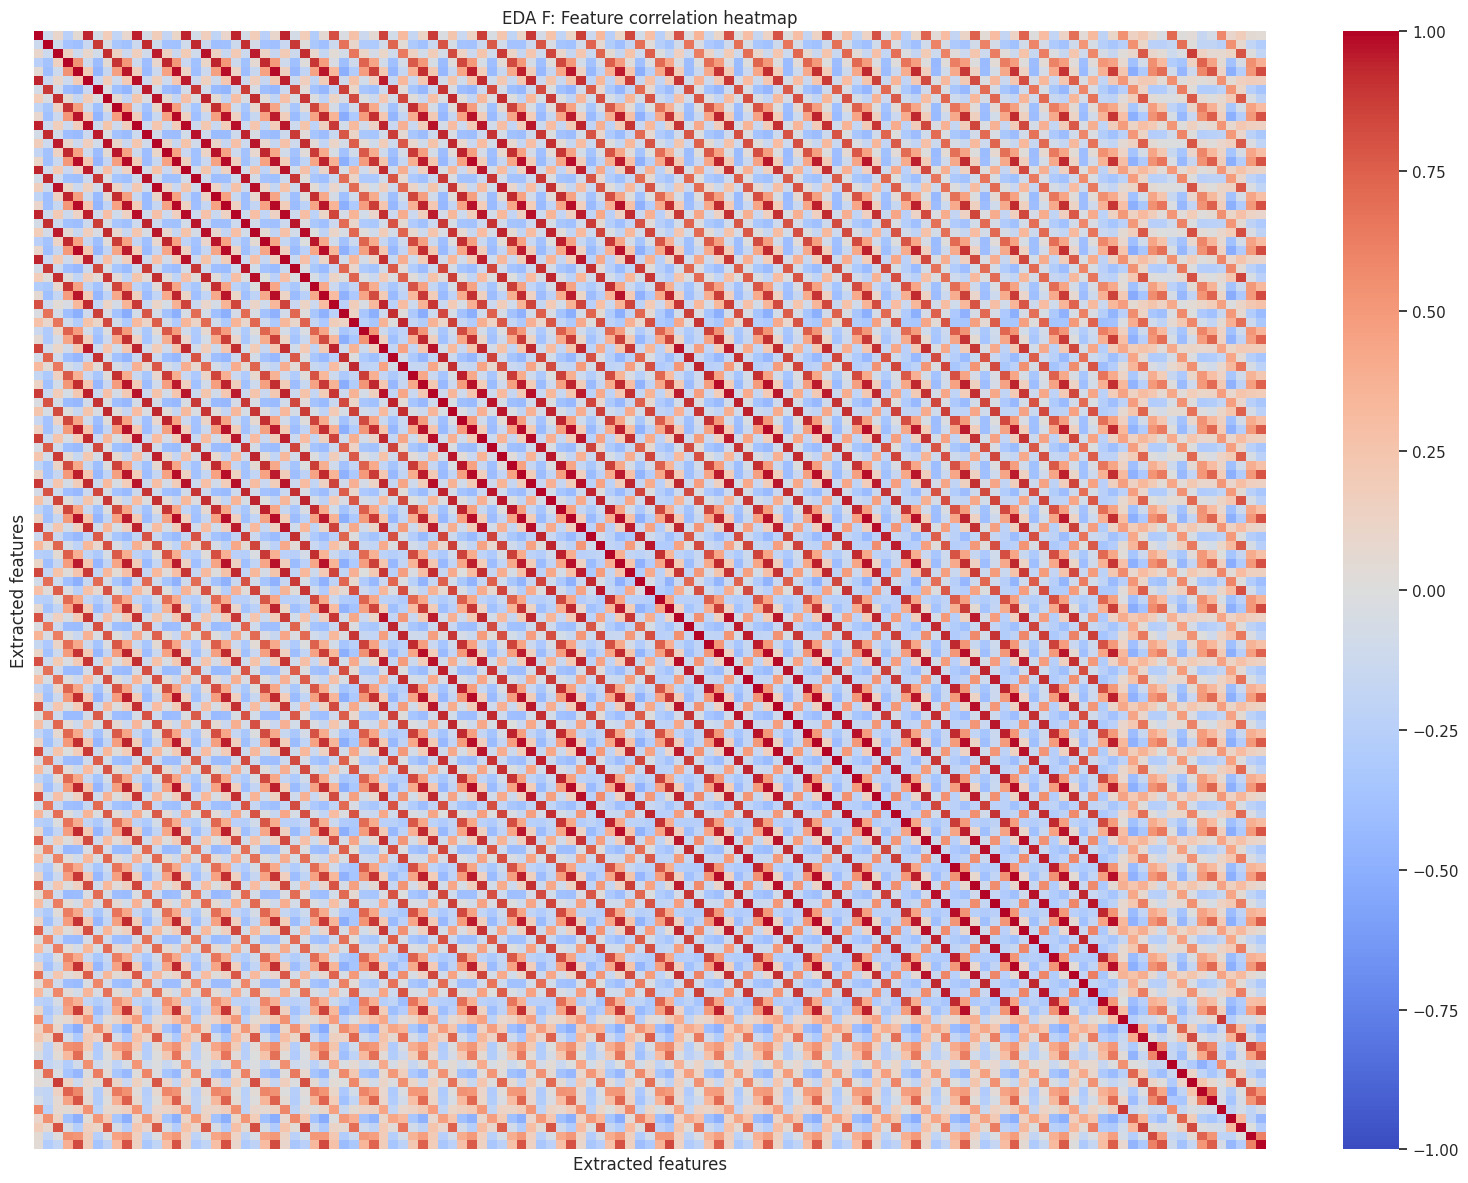

In [37]:
# For feature-level correlation, we use the extracted feature table rather than the raw EEG sample

feature_corr = feature_df.corr(method="pearson")

plt.figure(figsize=(16, 12))
sns.heatmap(
    feature_corr,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    xticklabels=False,
    yticklabels=False
)

plt.title("EDA F: Feature correlation heatmap")
plt.xlabel("Extracted features")
plt.ylabel("Extracted features")
plt.tight_layout()
plt.show()

List highly correlated feature pairs

In [38]:
corr_upper = feature_corr.where(
    np.triu(np.ones(feature_corr.shape), k=1).astype(bool)
)

redundant_pairs = (
    corr_upper.stack()
    .rename("correlation")
    .reset_index()
)

redundant_pairs.columns = [
    "feature_1", "feature_2", "correlation"
]

redundant_pairs = redundant_pairs[
    redundant_pairs["correlation"].abs() >= 0.90
].sort_values(
    "correlation",
    key=lambda s: s.abs(),
    ascending=False
)

display(redundant_pairs.head(50))

,feature_1,feature_2,correlation
7289,EEG-14_gamma_relpower,EEG-Pz_gamma_relpower,0.993895
7429,EEG-Pz_gamma_relpower,EEG-15_gamma_relpower,0.993468
6719,EEG-11_gamma_relpower,EEG-12_gamma_relpower,0.992464
7319,EEG-Pz_logvar,EEG-15_logvar,0.992329
7159,EEG-14_logvar,EEG-Pz_logvar,0.992118
1199,EEG-1_logvar,EEG-2_logvar,0.990698
6479,EEG-10_gamma_relpower,EEG-11_gamma_relpower,0.990395
6269,EEG-10_logvar,EEG-11_logvar,0.990280
4594,EEG-Cz_logvar,EEG-7_logvar,0.990245
6529,EEG-11_logvar,EEG-12_logvar,0.990206


# EDA - G (PCA, t-SNE and UMAP)

We will reduce the feature matrix to two dimensions and color each point by its motor-imagery class.

First, handle invalid feature values and standardize the features

In [39]:
# Remove features with no finite values.
valid_cols = feature_df.columns[
    np.isfinite(feature_df).any(axis=0)
]

F = feature_df[valid_cols].copy()

# Replace missing/infinite values with the column median.
F = F.replace([np.inf, -np.inf], np.nan)
F = F.fillna(F.median()).fillna(0)

scaler = StandardScaler()
F_scaled = scaler.fit_transform(F)

print("Scaled feature matrix:", F_scaled.shape)

Scaled feature matrix: (2592, 125)


For exploratory visualization, the following cell fits PCA

In [40]:
pca = PCA(n_components=2, random_state=42)
pca_result = pca.fit_transform(F_scaled)

pca_df = pd.DataFrame({
    "PC1": pca_result[:, 0],
    "PC2": pca_result[:, 1],
    "class": y,
    "subject": metadata["subject"].values
})

print(
    "Explained variance by PC1 and PC2:",
    pca.explained_variance_ratio_
)

fig = px.scatter(
    pca_df,
    x="PC1",
    y="PC2",
    color="class",
    symbol="subject",
    title="EDA G: PCA of EEG trial features",
    hover_data=["subject", "class"]
)

fig.show()

Explained variance by PC1 and PC2: [0.32678574 0.24597638]


run t-SNE. For a first experiment, use a subset to keep execution time manageable

In [41]:
rng = np.random.default_rng(42)

n_vis = min(1500, len(F_scaled))
indices = rng.choice(len(F_scaled), n_vis, replace=False)

F_vis = F_scaled[indices]
y_vis = y[indices]
subjects_vis = metadata["subject"].to_numpy()[indices]

tsne = TSNE(
    n_components=2,
    perplexity=30,
    init="pca",
    learning_rate="auto",
    random_state=42
)

tsne_result = tsne.fit_transform(F_vis)

tsne_df = pd.DataFrame({
    "tSNE1": tsne_result[:, 0],
    "tSNE2": tsne_result[:, 1],
    "class": y_vis,
    "subject": subjects_vis
})

fig = px.scatter(
    tsne_df,
    x="tSNE1",
    y="tSNE2",
    color="class",
    hover_data=["subject"],
    title="EDA G: t-SNE of EEG trial features"
)

fig.show()

UMAP

In [ ]:
import umap

umap_model = umap.UMAP(
    n_components=2,
    n_neighbors=15,
    min_dist=0.1,
    random_state=42
)

umap_result = umap_model.fit_transform(F_scaled)

umap_df = pd.DataFrame({
    "UMAP1": umap_result[:, 0],
    "UMAP2": umap_result[:, 1],
    "class": y,
    "subject": metadata["subject"].values
})

fig = px.scatter(
    umap_df,
    x="UMAP1",
    y="UMAP2",
    color="class",
    hover_data=["subject"],
    title="EDA G: UMAP of EEG trial features"
)

fig.show()

# EDA - H (Interactive EEG signal plot)

In [42]:
trial_idx = 0
channel_idx = 0

time = np.arange(X.shape[2]) / sfreq
signal = X[trial_idx, channel_idx, :]

signal_df = pd.DataFrame({
    "time_seconds": time,
    "amplitude_uV": signal
})

trial_class = y[trial_idx]
trial_subject = metadata.iloc[trial_idx]["subject"]

fig = px.line(
    signal_df,
    x="time_seconds",
    y="amplitude_uV",
    title=(
        f"EDA H: EEG waveform — {channel_names[channel_idx]} | "
        f"Subject {trial_subject} | {trial_class}"
    ),
    labels={
        "time_seconds": "Time (seconds)",
        "amplitude_uV": "Amplitude (µV)"
    }
)

fig.show()

# Export the EDA results to Google Drive

In [44]:
OUTPUT_DIR = os.path.join(DATA_DIR, "EDA_Results")
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Safe export helper to handle unexecuted notebook steps cleanly
def safe_to_csv(df_name, filename):
    if df_name in globals():
        globals()[df_name].to_csv(os.path.join(OUTPUT_DIR, filename), index=(False if "statistics" not in filename else True))
        print(f" Saved: {filename}")
    else:
        print(f" Skipped: {filename} ({df_name} is not defined)")

print("Exporting EDA results to Google Drive...")
safe_to_csv("file_summary_df", "file_summary.csv")
safe_to_csv("recording_summary_df", "recording_summary.csv")
safe_to_csv("class_balance", "class_balance.csv")
safe_to_csv("channel_stats", "channel_statistics.csv")
safe_to_csv("outlier_summary", "outlier_summary.csv")
safe_to_csv("high_corr_pairs", "channel_correlations.csv")
safe_to_csv("redundant_pairs", "feature_correlations.csv")
safe_to_csv("eda_df", "eda_feature_table.csv")
safe_to_csv("pca_df", "pca_results.csv")
safe_to_csv("tsne_df", "tsne_results.csv")
safe_to_csv("umap_df", "umap_results.csv")

print("\nDone! All available EDA files are saved to:", OUTPUT_DIR)

Exporting EDA results to Google Drive...
 Saved: file_summary.csv
 Saved: recording_summary.csv
 Saved: class_balance.csv
 Saved: channel_statistics.csv
 Saved: outlier_summary.csv
 Saved: channel_correlations.csv
 Saved: feature_correlations.csv
 Saved: eda_feature_table.csv
 Saved: pca_results.csv
 Saved: tsne_results.csv
 Skipped: umap_results.csv (umap_df is not defined)

Done! All available EDA files are saved to: /content/drive/MyDrive/475_mini_proj/EDA_Results
